# ¿Cómo se compara un resolvedor de orden mayor? RK45 frente al Euler hacia adelante del motor

**Pregunta:** El motor integra las ecuaciones SIR con Euler hacia adelante. ¿Cuánto más exacto es el resolvedor estándar de orden mayor, Dormand-Prince RK45, sobre los mismos casos, a qué costo en evaluaciones del lado derecho, y qué cambiaría en los números que reporta el ejemplo?

- **Nivel:** 3, Estado del arte
- **Requisitos:** notebook 02 de este tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes correr el resolvedor de referencia del ecosistema científico de Python sobre el mismo sistema SIR del motor, usar un segundo resolvedor independiente como verdad, y comparar los dos métodos por el error según el paso y por el error según el costo. Ves por qué un método de orden mayor cambia la relación entre exactitud y trabajo, y qué cuesta en el ejemplo la elección de Euler hacia adelante.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 scipy==1.18.1
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

SciPy es aquí la implementación de referencia fijada del estado del arte: el método propio del producto sigue siendo el motor. La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import derivatives, simulate

for name in ("numpy", "matplotlib", "scipy"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2
scipy 1.18.1


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

La comparación necesita primero el lado propio del motor, tomado de los notebooks anteriores. `simulate` de `data-pipeline/pipeline/model/sir.py` es Euler hacia adelante con paso de un cuarto de día: evalúa el lado derecho del sistema SIR una vez por paso, de modo que en 160 días su costo es de 640 evaluaciones, y su error es de primer orden en el paso. La celda lo corre sobre el caso epidémico y guarda su malla de tiempo, en la que se le pedirá la respuesta a todos los demás resolvedores.

In [2]:
# el motor en el caso epidémico: su número de pasos, que es también su número de evaluaciones del lado derecho
p = params_of("EX02_epidemic")
euler = simulate(p)
grid = np.array(euler.t)
print(f"pasos: {len(euler.t) - 1}, evaluaciones: {len(euler.t) - 1}")
print(f"pico {euler.peak_I:.0f}, el día {euler.t_peak:.2f}, tasa de ataque {euler.attack_rate:.6f}")

pasos: 640, evaluaciones: 640
pico 27345, el día 24.25, tasa de ataque 0.923654


## Estado del arte

El método estándar para ecuaciones diferenciales ordinarias no rígidas es un par de Runge-Kutta embebido. Dormand y Prince (1980) construyeron el par que hay detrás de RK45: avanza con una fórmula de quinto orden, la compara con una de cuarto para estimar el error local, y usa esa estimación para elegir el paso siguiente, de modo que quien lo usa fija una tolerancia y no un paso. Un paso cuesta seis evaluaciones del lado derecho. Hairer, Norsett y Wanner (1993) desarrollan la teoría y el método DOP853 de octavo orden que este notebook usa como verdad. SciPy implementa ambos en `solve_ivp` (Virtanen et al., 2020); la versión 1.18.1 es aquí la implementación de referencia fijada.

El lado derecho del SIR, que el resolvedor necesita como función, es `derivatives` de `data-pipeline/pipeline/model/sir.py`: la misma función de la que el motor toma sus pasos de Euler, de modo que ambos métodos integran un único enunciado del modelo y el notebook no define ninguno. La celda siguiente resuelve el caso epidémico con DOP853 con una tolerancia de $10^{-12}$ e imprime el costo y los números que fijan la verdad.

In [3]:
# un curso de referencia de un resolvedor de octavo orden a 1e-12, con el lado derecho del propio motor
y0 = [p.N - p.I0, p.I0, 0.0]
par = (p.beta, p.gamma, p.N)
reference = solve_ivp(derivatives, (0, p.days), y0, args=par, method="DOP853", t_eval=grid, rtol=1e-12, atol=1e-9)
ref_i = reference.y[1]
print(f"referencia: {reference.nfev} evaluaciones, pico {ref_i.max():.2f}", end=", ")
print(f"R/N final {reference.y[2, -1] / p.N:.6f}")

referencia: 1610 evaluaciones, pico 26867.38, R/N final 0.920487


La referencia necesitó 1610 evaluaciones para sostener $10^{-12}$ y pone el pico en 26867,38 personas sobre la malla del motor y la parte final en 0,920487, el valor que dio la relación del tamaño final en el tema anterior. Dos caminos independientes hacia el mismo número son toda la confirmación que el ejemplo puede pedir. Ahora RK45 con cuatro tolerancias, desde el valor por defecto de SciPy, $10^{-3}$, hasta $10^{-8}$. La celda informa, para cada una, las evaluaciones que usó y el mayor error de su curva de infectados frente a la referencia como parte de la población, con la corrida de Euler del motor en los mismos términos.

In [4]:
# RK45 de Dormand-Prince con cuatro tolerancias, y el mayor error de cada curso frente a la referencia
errors = {"Euler": np.max(np.abs(np.array(euler.I) - ref_i)) / p.N}
costs = {"Euler": len(euler.t) - 1}
for rtol in (1e-3, 1e-4, 1e-6, 1e-8):
    run = solve_ivp(derivatives, (0, p.days), y0, args=par, method="RK45", t_eval=grid, rtol=rtol, atol=1e-6)
    errors[f"RK45 {rtol:g}"] = np.max(np.abs(run.y[1] - ref_i)) / p.N
    costs[f"RK45 {rtol:g}"] = run.nfev
for label in errors:
    print(f"{label:12s} {costs[label]:5d} evaluaciones   error máx. {errors[label]:.2e}")

Euler          640 evaluaciones   error máx. 2.01e-02
RK45 0.001     200 evaluaciones   error máx. 1.93e-03
RK45 0.0001    284 evaluaciones   error máx. 6.88e-05
RK45 1e-06     554 evaluaciones   error máx. 5.37e-07
RK45 1e-08    1028 evaluaciones   error máx. 7.46e-09


RK45 con la tolerancia más laxa, 200 evaluaciones, ya comete un error de 1,93e-03, diez veces menor que el 2,01e-02 del motor con 640. Con $10^{-6}$ usa 554 evaluaciones, 13 por ciento menos que el motor, y su error es de 5,37e-07, unas 37000 veces menor. La comparación todavía no está en igualdad: RK45 elige sus propios pasos. Para comparar los métodos con un mismo paso, la celda siguiente recorre $h$ desde 2 hasta 0,125 días, corre Euler en cada uno y obliga a RK45 a dar exactamente ese paso, limitando el tamaño del paso y poniendo una tolerancia absurdamente laxa, de modo que todo paso se acepta. Imprime ambos errores y la pendiente de cada uno en ejes logarítmicos.

In [5]:
# el error según el paso: Euler con cinco pasos, y RK45 forzado a dar exactamente los mismos pasos
steps = [2.0, 1.0, 0.5, 0.25, 0.125]
euler_error = []
rk_error = []
for h in steps:
    g = np.arange(0, p.days + 1e-9, h)
    exact = solve_ivp(derivatives, (0, p.days), y0, args=par, method="DOP853", t_eval=g, rtol=1e-12, atol=1e-9).y[1]
    euler_error.append(np.max(np.abs(np.array(simulate(p, h).I) - exact)) / p.N)
    cap = dict(first_step=h, max_step=h, rtol=1e6, atol=1e6)
    fixed = solve_ivp(derivatives, (0, p.days), y0, args=par, method="RK45", t_eval=g, **cap)
    rk_error.append(np.max(np.abs(fixed.y[1] - exact)) / p.N)
    e1, e2 = euler_error[-1], rk_error[-1]
    print(f"h = {h:5.3f}  Euler {e1:.2e}  RK45 {e2:.2e}  Euler / RK45 {e1 / e2:.1e}")
slope_euler = np.polyfit(np.log(steps), np.log(euler_error), 1)[0]
slope_rk = np.polyfit(np.log(steps), np.log(rk_error), 1)[0]
print(f"pendientes del log del error contra el log del paso Euler {slope_euler:.2f}, RK45 {slope_rk:.2f}")

h = 2.000  Euler 1.35e-01  RK45 8.34e-06  Euler / RK45 1.6e+04
h = 1.000  Euler 7.54e-02  RK45 3.76e-07  Euler / RK45 2.0e+05
h = 0.500  Euler 3.96e-02  RK45 1.40e-08  Euler / RK45 2.8e+06
h = 0.250  Euler 2.01e-02  RK45 4.75e-10  Euler / RK45 4.2e+07
h = 0.125  Euler 1.01e-02  RK45 1.55e-11  Euler / RK45 6.5e+08
pendientes del log del error contra el log del paso Euler 0.94, RK45 4.77


La celda siguiente dibuja los dos errores contra el paso en ejes logarítmicos.

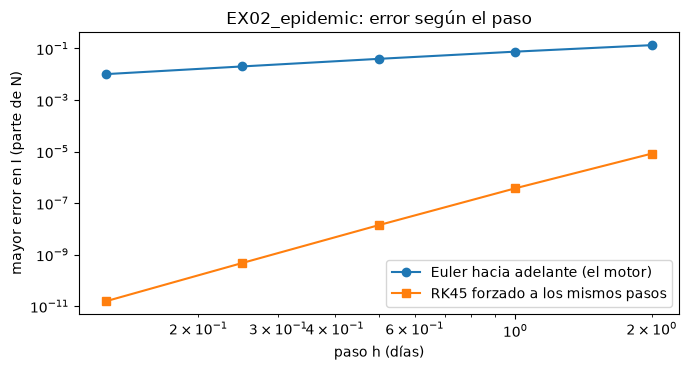

In [6]:
# dibuja los dos errores contra el paso en ejes logarítmicos
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(steps, euler_error, "o-", label="Euler hacia adelante (el motor)")
ax.loglog(steps, rk_error, "s-", label="RK45 forzado a los mismos pasos")
ax.set_xlabel("paso h (días)")
ax.set_ylabel("mayor error en I (parte de N)")
ax.set_title("EX02_epidemic: error según el paso")
ax.legend()
fig.tight_layout()
plt.show()

Ambos errores caen sobre rectas, con pendientes muy distintas: 0,94 para Euler, cerca de su 1 teórico, y 4,77 para RK45, cerca de su 5 teórico. Reducir el paso a la mitad reduce a la mitad el error de Euler y divide el de RK45 en unas 30 veces. Con el paso propio del motor, 0,25 días, los dos métodos difieren en un factor de 4,2e+07. La imagen favorece a RK45 porque un paso de RK45 cuesta seis evaluaciones y uno de Euler cuesta una, una diferencia que el gráfico esconde; la figura siguiente cobra el costo.

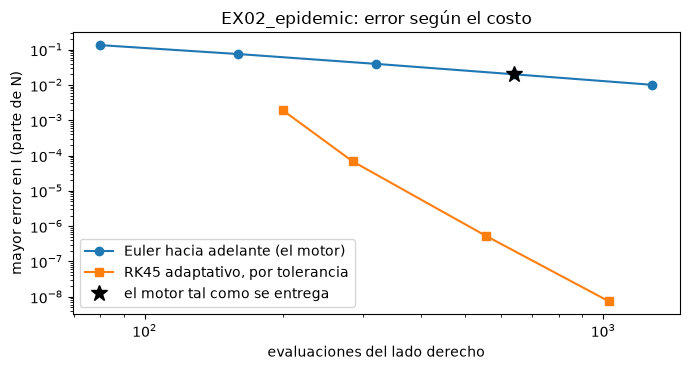

In [7]:
# dibuja el error contra las evaluaciones del lado derecho: Euler con sus pasos, RK45 adaptativo con sus tolerancias
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog([p.days / h for h in steps], euler_error, "o-", label="Euler hacia adelante (el motor)")
adaptive = [k for k in costs if k != "Euler"]
ax.loglog([costs[k] for k in adaptive], [errors[k] for k in adaptive], "s-", label="RK45 adaptativo, por tolerancia")
ax.plot([costs["Euler"]], [errors["Euler"]], "k*", markersize=12, label="el motor tal como se entrega")
ax.set_xlabel("evaluaciones del lado derecho")
ax.set_ylabel("mayor error en I (parte de N)")
ax.set_title("EX02_epidemic: error según el costo")
ax.legend()
fig.tight_layout()
plt.show()

Cobrado por costo, la imagen sigue siendo desigual. La línea de Euler cae despacio, una década de error por década de trabajo, y termina en la estrella del motor: 2,01e-02 con 640 evaluaciones. Los puntos de RK45 adaptativo caen mucho más rápido y llegan a 7,46e-09 con 1028 evaluaciones, con 554 evaluaciones suficientes para 5,37e-07. Si se extiende la línea de Euler siguiendo su pendiente, necesitaría unos 24 millones de evaluaciones para igualar el segundo punto de RK45, algo que la figura deja fuera del eje. Esto vale para un sistema suave y no rígido como este; la figura no dice nada sobre uno rígido, donde los métodos explícitos de cualquier orden fallan por otra razón.

La última celda hace la misma comparación sobre cada caso con personas infectadas, con el paso del motor para Euler y con $10^{-6}$ para RK45, e imprime el error del pico de cada uno. Responde si el caso epidémico es típico.

In [8]:
# la misma comparación en cada caso con infectados: el error del pico del motor y de RK45 con rtol 1e-6
print(f"{'caso':18s} {'err. pico Euler':>12s} {'err. pico RK45':>12s} {'evals':>8s}")
for case_id in CASES:
    q = params_of(case_id)
    if q.I0 == 0:
        continue
    own = simulate(q)
    qg = np.array(own.t)
    q0, qp = [q.N - q.I0, q.I0, 0.0], (q.beta, q.gamma, q.N)
    truth = solve_ivp(derivatives, (0, q.days), q0, args=qp, method="DOP853", t_eval=qg, rtol=1e-12, atol=1e-9).y[1]
    rk = solve_ivp(derivatives, (0, q.days), q0, args=qp, method="RK45", t_eval=qg, rtol=1e-6, atol=1e-6)
    err_euler = own.peak_I / truth.max() - 1
    err_rk = rk.y[1].max() / truth.max() - 1
    print(f"{case_id:18s} {err_euler:+12.2e} {err_rk:+12.2e} {rk.nfev:8d}")

caso               err. pico Euler err. pico RK45    evals
EX01_subcritical      +0.00e+00    +0.00e+00      212
EX02_epidemic         +1.78e-02    +1.63e-07      554
EX03_fast_burn        +3.34e-02    +2.83e-07      620
EX04_slow_spread      +3.89e-03    +1.06e-06      176


## Resultados

**Respuesta:** En el caso epidémico el Euler hacia adelante del motor, con 640 evaluaciones, comete un mayor error de 2,01e-02 de la población en la curva de infectados, frente a 1,93e-03 de RK45 con su tolerancia por defecto y 200 evaluaciones y 5,37e-07 de RK45 con $10^{-6}$ y 554 evaluaciones: RK45 es unas 37000 veces más exacto con 13 por ciento menos trabajo. Con pasos iguales el error de Euler escala con pendiente 0,94 y el de RK45 con pendiente 4,77, de modo que con el paso del motor, 0,25 días, difieren en un factor de 4,2e+07. En el pico, Euler queda alto en 1,78e-02 para el caso epidémico y en 3,34e-02 para la combustión rápida, mientras RK45 queda a 1,06e-06 en todos los casos. Reproducir los números del ejemplo con RK45 bajaría el pico del caso epidémico de 27345 a unas 26867 personas y su tasa de ataque de 0,923654 a 0,920487.

El resultado vale para un sistema suave y no rígido, y el costo contado en evaluaciones no es un tiempo: también importa la sobrecarga por llamada de un resolvedor, que un lazo de Python puro como el del motor esconde. El motor conserva Euler hacia adelante por diseño, un integrador de una línea que su gemelo en TypeScript del puerto web reproduce paso a paso; este notebook mide lo que cuesta esa elección, y la respuesta es un pico entre 0,4 y 3,3 por ciento alto, según el caso.

## Resumen

- RK45 (Dormand y Prince) con una tolerancia de $10^{-6}$ es unas 37000 veces más exacto que el paso de Euler del motor en el caso epidémico, con 13 por ciento menos evaluaciones.
- Con pasos iguales las pendientes del error son 0,94 para Euler y 4,77 para RK45: órdenes 1 y 5.
- La ventaja se mantiene en los cuatro casos con personas infectadas: el error del pico baja de hasta 3,3 por ciento a cerca de 1e-06.
- El Euler hacia adelante del motor es una elección de diseño por simplicidad y paridad con el puerto web; su costo es un pico 0,4 a 3,3 por ciento alto.
- Siguiente: el tema 02 pregunta cuándo despega un brote y qué tan grande se vuelve.

## Referencias

- Hairer, E., Norsett, S. P. y Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- Dormand, J. R. y Prince, P. J. (1980). A family of embedded Runge-Kutta formulae. Journal of Computational and Applied Mathematics. https://doi.org/10.1016/0771-050X(80)90013-3
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. Nature Methods. https://doi.org/10.1038/s41592-019-0686-2
- SciPy, https://pypi.org/project/scipy/ (fijado en `notebooks/requirements.txt`).
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).